# DBSCAN - Phân cụm theo mật độ

**Báo cáo giữa kỳ - Học máy**

| Phần | Thành viên | MSSV |
| --- | --- | --- |
| I. Dữ liệu và vùng lân cận | Huỳnh Cao Trung Đức | 24133012 |
| II. Định nghĩa và cài đặt DBSCAN | Bùi Nguyễn Nguyên Khang | 24133902 |
| III. Chạy demo và đối chiếu kết quả | Phạm Đức Khoa | 24149170 |

DBSCAN (Density-Based Spatial Clustering of Applications with Noise) là thuật toán phân cụm không giám sát. Thuật toán mở rộng cụm từ các vùng đủ mật độ và nhận diện điểm nhiễu. Số cụm được xác định trong khi chạy.

## Phần I. Dữ liệu và vùng lân cận

**Huỳnh Cao Trung Đức - 24133012**

### 1. Bài toán và dữ liệu minh họa

Mỗi điểm biểu diễn một nền kinh tế giả lập qua hai chỉ tiêu: tăng trưởng GDP (%) và tỷ lệ thất nghiệp (%). Nhiệm vụ là tìm các nhóm điểm nằm gần nhau và nhận diện các điểm ở vùng thưa. Các mã A, B và N giúp theo dõi từng điểm trên hình. Thuật toán chỉ nhận hai cột tọa độ.

In [1]:
from collections import deque

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

data = pd.DataFrame([
    ("A1", 2.0, 4.0), ("A2", 2.4, 4.0), ("A3", 2.0, 4.3),
    ("A4", 2.0, 3.7), ("A5", 2.8, 4.0),
    ("B1", 5.0, 7.0), ("B2", 5.3, 7.0), ("B3", 5.0, 7.3),
    ("B4", 5.0, 6.7), ("B5", 5.7, 7.0),
    ("N1", 3.2, 4.0), ("N2", 7.0, 3.0),
], columns=["Điểm", "Tăng trưởng GDP (%)", "Thất nghiệp (%)"])

names = data["Điểm"].to_numpy()
points = data[["Tăng trưởng GDP (%)", "Thất nghiệp (%)"]].to_numpy()
display(data)

,Điểm,Tăng trưởng GDP (%),Thất nghiệp (%)
0,A1,2.0,4.0
1,A2,2.4,4.0
2,A3,2.0,4.3
3,A4,2.0,3.7
4,A5,2.8,4.0
5,B1,5.0,7.0
6,B2,5.3,7.0
7,B3,5.0,7.3
8,B4,5.0,6.7
9,B5,5.7,7.0


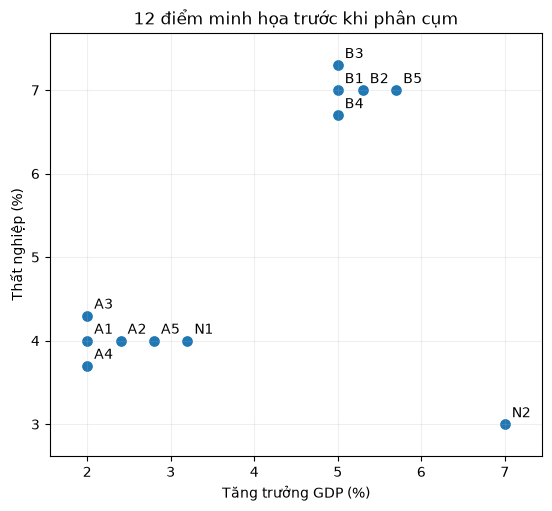

In [2]:
def label_points(ax, indexes):
    for i in indexes:
        ax.annotate(names[i], points[i], xytext=(5, 5), textcoords="offset points")
    ax.set(xlabel="Tăng trưởng GDP (%)", ylabel="Thất nghiệp (%)", aspect="equal")
    ax.grid(alpha=0.2)
    ax.margins(0.09)

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
ax.scatter(points[:, 0], points[:, 1], color="C0", s=45)
label_points(ax, range(len(points)))
ax.set_title("12 điểm minh họa trước khi phân cụm")
plt.show()

### 2. Khoảng cách và vùng lân cận

Trong ví dụ này, khoảng cách Euclid giữa hai điểm $p=(p_x,p_y)$ và $q=(q_x,q_y)$ được tính theo công thức:

$$d(p,q)=\sqrt{(p_x-q_x)^2+(p_y-q_y)^2}.$$

- **eps** là bán kính vùng lân cận. Vùng này gồm các điểm cách tâm tối đa eps, kể cả các điểm đúng trên đường tròn. Demo chọn eps = 0,55.
- **min_samples** (MinPts trong bài báo gốc) là số điểm tối thiểu trong vùng lân cận để xác định một điểm lõi. Tính cả chính điểm đang xét. Demo chọn min_samples = 4.

Ví dụ, A1 có tọa độ $(2{,}0; 4{,}0)$ và A2 có tọa độ $(2{,}4; 4{,}0)$. Hai điểm cùng tung độ nên khoảng cách là $|2{,}4-2{,}0|=0{,}4$. Vì $0{,}4\leq 0{,}55$, A2 nằm trong vùng lân cận của A1.

In [3]:
eps = 0.55
min_samples = 4

def points_in_radius(points, index, eps):
    difference = points - points[index]
    distances = np.sqrt((difference ** 2).sum(axis=1))
    return np.flatnonzero(distances <= eps)

nearby = points_in_radius(points, 0, eps)
print(f"Trong bán kính eps quanh A1 có {len(nearby)} điểm:", ", ".join(names[nearby]))

Trong bán kính eps quanh A1 có 4 điểm: A1, A2, A3, A4


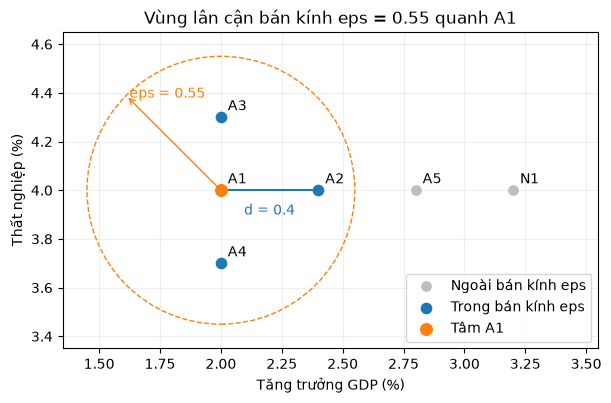

In [4]:
area_a = np.flatnonzero(points[:, 0] < 4)
fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
outside = np.setdiff1d(area_a, nearby)
ax.scatter(points[outside, 0], points[outside, 1], color="0.75", s=45, label="Ngoài bán kính eps")
ax.scatter(points[nearby, 0], points[nearby, 1], color="C0", s=55, zorder=3, label="Trong bán kính eps")
ax.scatter(*points[0], color="C1", s=70, zorder=4, label="Tâm A1")
ax.add_patch(plt.Circle(points[0], eps, fill=False, linestyle="--", color="C1"))
r = eps / np.sqrt(2)
ax.annotate("", xy=(points[0, 0] - r, points[0, 1] + r), xytext=points[0], arrowprops=dict(arrowstyle="->", color="C1"))
ax.text(1.78, 4.38, f"eps = {eps}", color="C1", ha="center")
ax.plot(points[[0, 1], 0], points[[0, 1], 1], color="C0")
ax.text(2.2, 3.9, "d = 0.4", ha="center", color="C0")
label_points(ax, area_a)
ax.set(xlim=(1.35, 3.55), ylim=(3.35, 4.65), title=f"Vùng lân cận bán kính eps = {eps} quanh A1")
ax.legend(loc="lower right")
plt.show()

## Phần II. Định nghĩa và cài đặt DBSCAN

**Bùi Nguyễn Nguyên Khang - 24133902**

### 3. Điểm lõi, điểm biên và điểm nhiễu

| Loại điểm | Điều kiện | Ví dụ |
| --- | --- | --- |
| **Lõi** | Có ít nhất min_samples điểm trong vùng lân cận. | A1 có 4 điểm. |
| **Biên** | Có dưới min_samples điểm trong vùng lân cận, nhưng nằm trong bán kính eps của ít nhất một điểm lõi. | A5 có 3 điểm và nằm trong bán kính của lõi A2. |
| **Nhiễu** | Có dưới min_samples điểm trong vùng lân cận và nằm ngoài bán kính eps của mọi điểm lõi. | N1 gần điểm biên A5, còn lõi gần nhất là A2 cách 0,8. |

Hai điểm lõi thuộc cùng cụm nếu nối được với nhau qua một chuỗi điểm lõi, với mỗi bước dài tối đa eps. Các điểm biên được gắn vào cụm qua một điểm lõi. Đây là ý tưởng **liên thông theo mật độ**.

### 4. Tự cài đặt và mở rộng cụm

1. Với mỗi điểm, tìm các điểm nằm trong bán kính eps. Đánh dấu những điểm đủ điều kiện làm lõi.
2. Chọn một điểm lõi chưa có cụm, gán nhãn cụm mới và đưa điểm đó vào hàng đợi.
3. Lấy từng điểm lõi khỏi đầu hàng đợi. Gán nhãn cho các điểm lân cận chưa thuộc cụm. Nếu một điểm vừa được gán nhãn cũng là điểm lõi, thêm nó vào cuối hàng đợi.
4. Khi hàng đợi rỗng, chuyển sang điểm lõi chưa có cụm tiếp theo. Các điểm còn giữ nhãn -1 sau khi duyệt hết là nhiễu.

In [5]:
def dbscan(points, eps, min_samples):
    nearby = [points_in_radius(points, i, eps) for i in range(len(points))]
    is_core = np.array([len(group) for group in nearby]) >= min_samples
    labels = np.full(len(points), -1)
    cluster_id = 0

    for start in np.flatnonzero(is_core):
        if labels[start] != -1:
            continue
        labels[start] = cluster_id
        queue = deque([start])

        while queue:
            current = queue.popleft()
            for nearby_index in nearby[current]:
                if labels[nearby_index] != -1:
                    continue
                labels[nearby_index] = cluster_id
                if is_core[nearby_index]:
                    queue.append(nearby_index)
        cluster_id += 1

    return labels, is_core

Hình dưới theo dõi vùng lân cận của ba điểm trong quá trình hình thành cụm 0.

- Lõi **A1** mở cụm và đưa lõi A2 vào hàng đợi.
- Lõi **A2** được xét tiếp và đưa A5 vào cụm. A1 và A5 cách nhau 0,8, nhưng cả hai thuộc cùng cụm nhờ A2.
- Hình ở **A5** minh họa vì sao cụm dừng lại: A5 là điểm biên nên vùng lân cận của nó không được dùng để gán nhãn cho N1.

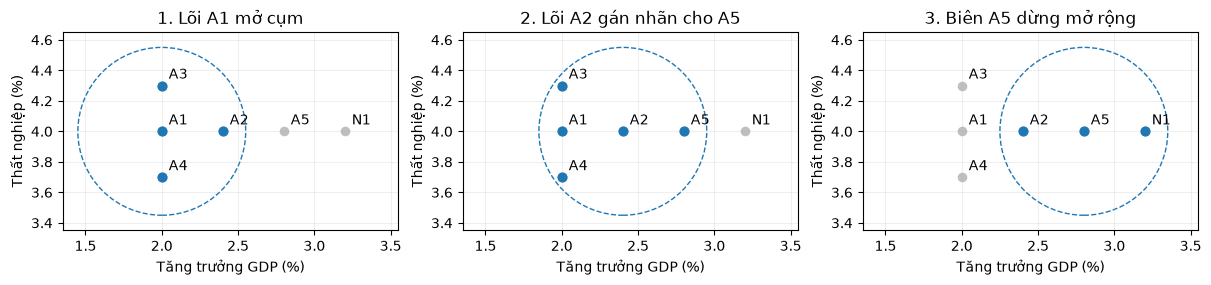

In [6]:
area = np.flatnonzero(points[:, 0] < 4)
centers = [0, 1, 4]
titles = ["1. Lõi A1 mở cụm", "2. Lõi A2 gán nhãn cho A5", "3. Biên A5 dừng mở rộng"]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), layout="constrained")
for ax, center, title in zip(axes, centers, titles):
    nearby = points_in_radius(points, center, eps)
    ax.scatter(points[area, 0], points[area, 1], color="0.75", s=35)
    ax.scatter(points[nearby, 0], points[nearby, 1], color="C0", s=40, zorder=3)
    ax.add_patch(plt.Circle(points[center], eps, fill=False, linestyle="--", color="C0"))
    label_points(ax, area)
    ax.set(xlim=(1.35, 3.55), ylim=(3.35, 4.65), title=title)
plt.show()

Trong hình, các chấm xanh là những điểm nằm trong vòng tròn của điểm đang xét. Ở khung thứ ba, N1 có màu xanh vì nằm gần A5. N1 vẫn nhận nhãn -1 vì nằm ngoài bán kính eps của mọi điểm lõi.

## Phần III. Chạy demo và đối chiếu kết quả

**Phạm Đức Khoa - 24149170**

### 5. Chạy DBSCAN trên 12 điểm

Nhãn 0 và 1 là mã của hai cụm được tạo lần lượt. Bảng cho biết nhãn, loại điểm và số điểm trong bán kính eps của từng quan sát.

In [7]:
labels, is_core = dbscan(points, eps, min_samples)
counts = [len(points_in_radius(points, i, eps)) for i in range(len(points))]
point_type = np.select([is_core, labels == -1], ["Lõi", "Nhiễu"], default="Biên")

result = pd.DataFrame({
    "Điểm": names, "Số điểm trong bán kính eps": counts, "Nhãn cụm": labels, "Loại điểm": point_type,
})
display(result)

,Điểm,Số điểm trong bán kính eps,Nhãn cụm,Loại điểm
0,A1,4,0,Lõi
1,A2,5,0,Lõi
2,A3,3,0,Biên
3,A4,3,0,Biên
4,A5,3,0,Biên
5,B1,4,1,Lõi
6,B2,5,1,Lõi
7,B3,3,1,Biên
8,B4,3,1,Biên
9,B5,2,1,Biên


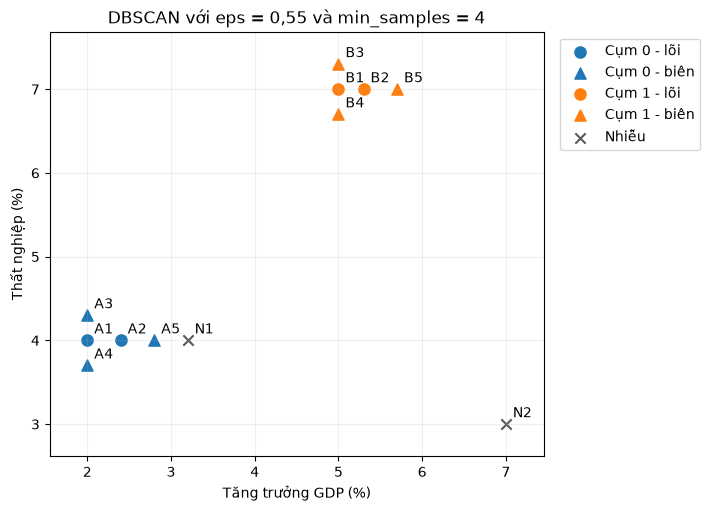

In [8]:
def plot_dbscan_result(ax, cluster_labels, core_mask):
    for cluster_id in sorted(set(cluster_labels) - {-1}):
        in_cluster = cluster_labels == cluster_id
        color = f"C{cluster_id}"
        for point_mask, marker, point_kind in [(core_mask, "o", "lõi"), (~core_mask, "^", "biên")]:
            selected = in_cluster & point_mask
            ax.scatter(points[selected, 0], points[selected, 1], color=color, s=65, marker=marker,
                       label=f"Cụm {cluster_id} - {point_kind}")

    noise_mask = cluster_labels == -1
    ax.scatter(points[noise_mask, 0], points[noise_mask, 1], color="0.35", s=55, marker="x", label="Nhiễu")
    label_points(ax, range(len(points)))


fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
plot_dbscan_result(ax, labels, is_core)
ax.set_title("DBSCAN với eps = 0,55 và min_samples = 4")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

### 6. Đối chiếu với kết quả tính tay

Với từng điểm, tính khoảng cách đến các điểm còn lại và giữ các điểm cách nó tối đa 0,55. Tính thêm chính điểm đó. Các kết quả trong bảng được ghi theo thứ tự mã điểm ở cột đầu.

| Điểm | Số điểm trong bán kính eps | Nhãn | Loại điểm |
| --- | --- | --- | --- |
| A1, A2, A3, A4, A5 | 4, 5, 3, 3, 3 | 0 | Lõi, lõi, biên, biên, biên |
| B1, B2, B3, B4, B5 | 4, 5, 3, 3, 2 | 1 | Lõi, lõi, biên, biên, biên |
| N1, N2 | 2, 1 | -1 | Nhiễu, nhiễu |

N1 chỉ có chính nó và điểm biên A5 trong vùng lân cận. Vùng lân cận của N2 chỉ có chính nó.

In [9]:
expected_counts = [4, 5, 3, 3, 3, 4, 5, 3, 3, 2, 2, 1]
expected_labels = [0] * 5 + [1] * 5 + [-1] * 2
expected_types = ["Lõi", "Lõi", "Biên", "Biên", "Biên"] * 2 + ["Nhiễu", "Nhiễu"]

assert counts == expected_counts
assert labels.tolist() == expected_labels
assert point_type.tolist() == expected_types
print("Số điểm trong bán kính eps, nhãn cụm và loại điểm đều khớp với kết quả tính tay cho cả 12 điểm.")

summary = pd.crosstab(result["Nhãn cụm"], result["Loại điểm"], margins=True, margins_name="Tổng")
display(summary)

Số điểm trong bán kính eps, nhãn cụm và loại điểm đều khớp với kết quả tính tay cho cả 12 điểm.


Loại điểm,Biên,Lõi,Nhiễu,Tổng
Nhãn cụm,,,,
-1,0,0,2,2
0,3,2,0,5
1,3,2,0,5
Tổng,6,4,2,12


### 7. Ảnh hưởng của bán kính eps

So sánh ba mức eps trên cùng 12 điểm với **min_samples = 4**. Mã và màu cụm được gán lại ở mỗi lần chạy.

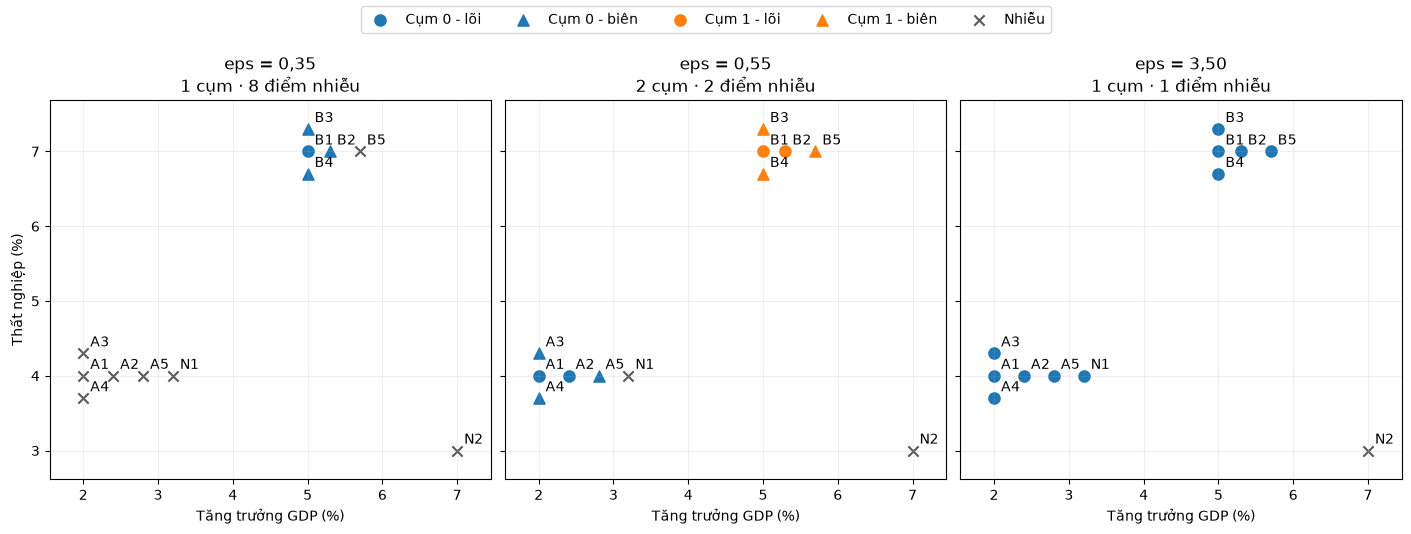

In [10]:
eps_values = [0.35, eps, 3.50]
fig, axes = plt.subplots(1, 3, figsize=(14, 5.4), sharex=True, sharey=True, layout="constrained")

for ax, radius in zip(axes, eps_values):
    scenario_labels, scenario_core = dbscan(points, radius, min_samples)
    plot_dbscan_result(ax, scenario_labels, scenario_core)
    n_clusters = len(set(scenario_labels) - {-1})
    n_noise = np.count_nonzero(scenario_labels == -1)
    radius_text = f"{radius:.2f}".replace(".", ",")
    ax.set_title(f"eps = {radius_text}\n{n_clusters} cụm · {n_noise} điểm nhiễu")
    ax.label_outer()

handles, legend_labels = axes[1].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="outside upper center", ncols=len(legend_labels))
plt.show()

**Kết luận.** Ở eps = 0,55, DBSCAN tìm được hai cụm và hai điểm nhiễu. Số điểm trong bán kính eps, nhãn và loại điểm đều khớp với tính tay ở cả 12 điểm. Ở eps = 0,35, có nhiều điểm nhiễu hơn. Đến eps = 3,50, hai vùng A và B nối thành một cụm.